# Práctica 3.4 Clasificación - Minería de Datos
**Facultad de Ingeniería, UNAM**

**Equipo:** Luis Angel Echevarria Aguilar, Leonardo Alan Lee Robles, Luna Alberto Darwin Leonel

## 1. Caso de negocio

### 1.1 Objetivo
**Personas con diabetes:** identificar las características principales que determinan que una persona puede tener diabetes, y construir un modelo que clasifique a cada persona como *con* o *sin* diabetes.

Un modelo así sirve como **herramienta de tamizaje**: prioriza a quién enviar a una prueba confirmatoria y señala qué indicadores clínicos conviene vigilar. No sustituye un diagnóstico médico.

### 1.2 Variable objetivo
`Tiene Diabetes` es **categórica binaria**: 1 = la persona tiene diabetes, 0 = no la tiene. Por eso el problema es de **clasificación**. El resto de las columnas son variables independientes, salvo `Persona`, que es un identificador: no se usa para entrenar, pero se conserva para identificar a las personas en los falsos positivos y falsos negativos.

### 1.3 Diccionario de variables
| Variable | Qué mide | Rol |
|---|---|---|
| `Persona` | Identificador de la persona | Identificador |
| `Num Embarazos` | Número de embarazos | Predictora |
| `N Glucosa` | Nivel de glucosa en sangre | Predictora |
| `Presion Arterial` | Presión arterial diastólica | Predictora |
| `Grosor de la Piel` | Grosor del pliegue cutáneo del tríceps | Predictora |
| `Urea` | Nivel de urea en sangre | Predictora |
| `Trigliceridos` | Nivel de triglicéridos | Predictora |
| `Lipoproteina BD` | Lipoproteína de baja densidad | Predictora |
| `N. Insulina` | Nivel de insulina | Predictora |
| `Masa Corporal` | Índice de masa corporal | Predictora |
| `Prediccion Diabetes` | Índice de predisposición por antecedentes familiares (*pedigree*); no es una predicción del resultado | Predictora |
| `Edad` | Edad en años | Predictora |
| `Tiene Diabetes` | 1 = con diabetes, 0 = sin diabetes | **Objetivo** |

In [ ]:
import os, datetime
try:                                    # silencia el DeprecationWarning de utcnow() en Colab
    import jupyter_client.session as _jc
    _jc.utcnow = lambda: datetime.datetime.now(datetime.timezone.utc)
except Exception:
    pass

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import StratifiedKFold, train_test_split, RepeatedStratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.inspection import permutation_importance
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, classification_report)
import warnings
warnings.filterwarnings('ignore')

# ---- Estilo de gráficas (colores validados para contraste y daltonismo) ----
AZUL, NARANJA, AQUA, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#898781'
COL_MODELO = {'Regresión Logística': AZUL, 'Random Forest': AQUA, 'Naive Bayes': NARANJA}
COL_CLASE = {0: AZUL, 1: NARANJA}
ETQ_CLASE = {0: 'Sin diabetes', 1: 'Con diabetes'}
DIV = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#d9443b'])
SEC = LinearSegmentedColormap.from_list('sec', ['#eaf1fb', '#2a78d6', '#0d2f5e'])
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'text.color': '#0b0b0b',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.8, 'axes.axisbelow': True, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'figure.dpi': 100})
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
pd.set_option('display.max_columns', 30)

### 1.4 Carga del archivo
Se carga `diabetes_demo.csv`. En Colab, si el archivo no está en la carpeta de trabajo, la celda abre el selector para subirlo.

In [ ]:
ARCHIVO = 'diabetes demo.csv'
if not os.path.exists(ARCHIVO):
    try:
        from google.colab import files
        print('Sube el archivo', ARCHIVO)
        ARCHIVO = list(files.upload().keys())[0]
    except ImportError:
        raise FileNotFoundError(f'No se encontró {ARCHIVO}')

df = pd.read_csv(ARCHIVO)
df.columns = df.columns.str.strip()
OBJETIVO = 'Tiene Diabetes'
print(f'Filas: {df.shape[0]} | Columnas: {df.shape[1]}')
display(df.head())

Filas: 829 | Columnas: 13


,Persona,Num Embarazos,N Glucosa,Presion Arterial,Grosor de la Piel,Urea,Trigliceridos,Lipoproteina BD,N. Insulina,Masa Corporal,Prediccion Diabetes,Edad,Tiene Diabetes
0,6710,1,199,76,43,6.0000,3.0000,0.8000,0,42.9000,1.3940,22,1
1,5710,0,198,66,32,2.0000,3.0000,0.6000,274,41.3000,0.5020,28,1
2,180,2,197,70,45,4.4000,3.0000,0.3000,543,30.5000,0.1580,53,1
3,2380,4,197,70,39,8.5000,5.0000,0.7000,744,36.7000,2.3290,31,0
4,4180,8,197,74,0,1.9000,2.0000,1.2000,0,25.9000,1.1910,39,1


## 2. Calidad de los datos

Se revisan nulos, duplicados y el identificador. Además, varias mediciones clínicas tienen valores en **0** que son fisiológicamente imposibles (nadie vivo tiene glucosa, presión arterial o índice de masa corporal en cero): en este tipo de datos el 0 significa **"no se midió"**. Esos ceros se tratan como faltantes y se reemplazan más adelante por la mediana del conjunto de entrenamiento. En `Num Embarazos` el 0 sí es un valor válido.

In [ ]:
display(pd.DataFrame({'tipo': df.dtypes.astype(str), 'nulos': df.isna().sum(), 'valores únicos': df.nunique()}))
print(f'Renglones duplicados (sin contar Persona): {df.drop(columns=["Persona"]).duplicated().sum()}')
rep = df['Persona'].duplicated(keep=False)
print(f'IDs de Persona repetidos: {df.loc[rep, "Persona"].nunique()} IDs en {rep.sum()} renglones. '
      'Sus mediciones son distintas, así que se tratan como personas diferentes y en los resultados se identifican por Persona + número de fila.')

CEROS_FALTANTES = ['N Glucosa', 'Presion Arterial', 'Grosor de la Piel', 'N. Insulina', 'Masa Corporal']
tab_ceros = pd.DataFrame({'Ceros': (df[CEROS_FALTANTES] == 0).sum(),
                          '% de registros': (df[CEROS_FALTANTES] == 0).mean() * 100}).sort_values('Ceros', ascending=False)
print('\nCeros que en realidad son valores faltantes:')
display(tab_ceros)

def preparar(d):
    """Convierte en NaN los ceros imposibles (no usa información de otras filas, así que no hay fuga de datos)."""
    d = d.copy()
    d[CEROS_FALTANTES] = d[CEROS_FALTANTES].replace(0, np.nan)
    return d

dfp = preparar(df)
PREDICTORAS = [c for c in df.columns if c not in ('Persona', OBJETIVO)]
display(dfp[PREDICTORAS].describe().T)

,tipo,nulos,valores únicos
Persona,int64,0,768
Num Embarazos,int64,0,17
N Glucosa,int64,0,136
Presion Arterial,int64,0,47
Grosor de la Piel,int64,0,51
Urea,float64,0,83
Trigliceridos,float64,0,54
Lipoproteina BD,float64,0,33
N. Insulina,int64,0,186
Masa Corporal,float64,0,248


Renglones duplicados (sin contar Persona): 0
IDs de Persona repetidos: 58 IDs en 119 renglones. Sus mediciones son distintas, así que se tratan como personas diferentes y en los resultados se identifican por Persona + número de fila.

Ceros que en realidad son valores faltantes:


,Ceros,% de registros
N. Insulina,405,48.8540
Grosor de la Piel,246,29.6743
Presion Arterial,38,4.5838
Masa Corporal,11,1.3269
N Glucosa,6,0.7238


,count,mean,std,min,25%,50%,75%,max
Num Embarazos,829.0000,3.8745,3.3458,0.0000,1.0000,3.0000,6.0000,17.0000
N Glucosa,823.0000,121.9016,30.6031,44.0000,100.0000,117.0000,141.0000,199.0000
Presion Arterial,791.0000,72.4539,12.3224,24.0000,64.0000,72.0000,80.0000,122.0000
Grosor de la Piel,583.0000,29.1904,10.4403,7.0000,22.0000,29.0000,36.0000,99.0000
Urea,829.0000,5.6165,3.9178,1.1000,3.6000,4.7000,6.0000,26.4000
Trigliceridos,829.0000,2.9134,1.6524,0.6000,1.6000,2.2000,4.0000,8.7000
Lipoproteina BD,829.0000,1.4497,3.0353,0.2000,0.6000,0.8000,1.3000,31.8000
N. Insulina,424.0000,156.5000,118.2400,14.0000,78.0000,126.0000,190.0000,846.0000
Masa Corporal,818.0000,32.5324,6.8635,18.2000,27.6000,32.4000,36.6000,67.1000
Prediccion Diabetes,829.0000,0.4690,0.3266,0.0780,0.2450,0.3700,0.6140,2.4200


## 3. Análisis Exploratorio de Datos (EDA)

Se analizan las variables independientes contra la objetivo para decidir cuáles utilizar: balance de clases, distribución de cada variable por clase, prueba de diferencia entre grupos, correlaciones y una decisión final comprobada con validación cruzada.

### 3.1 Balance de la variable objetivo
Si una clase es mucho más frecuente, la exactitud (*accuracy*) engaña: un modelo que diga siempre "sin diabetes" acertaría la proporción de la clase mayoritaria. Por eso más adelante se usa partición estratificada y métricas como sensibilidad, precisión, F1 y AUC.

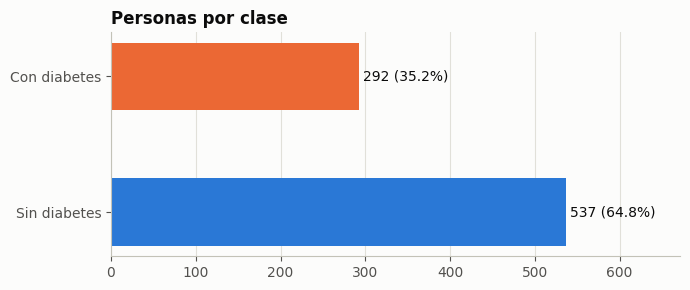

Línea base: predecir siempre "sin diabetes" daría una exactitud de 0.648


In [ ]:
cnt = df[OBJETIVO].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh([ETQ_CLASE[i] for i in cnt.index], cnt.values, color=[COL_CLASE[i] for i in cnt.index], height=.5)
for i, v in enumerate(cnt.values):
    ax.text(v + 5, i, f'{v} ({v / cnt.sum() * 100:.1f}%)', va='center', fontsize=10)
ax.set_xlim(0, cnt.max() * 1.25); ax.set_title('Personas por clase'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
print(f'Línea base: predecir siempre "sin diabetes" daría una exactitud de {cnt.max() / cnt.sum():.3f}')

### 3.2 Distribución de cada variable por clase
Cada panel compara la distribución de una variable entre personas con y sin diabetes (los faltantes se excluyen). Cuanto más separadas estén las dos curvas, más ayuda esa variable a distinguir las clases; si se enciman, aporta poco.

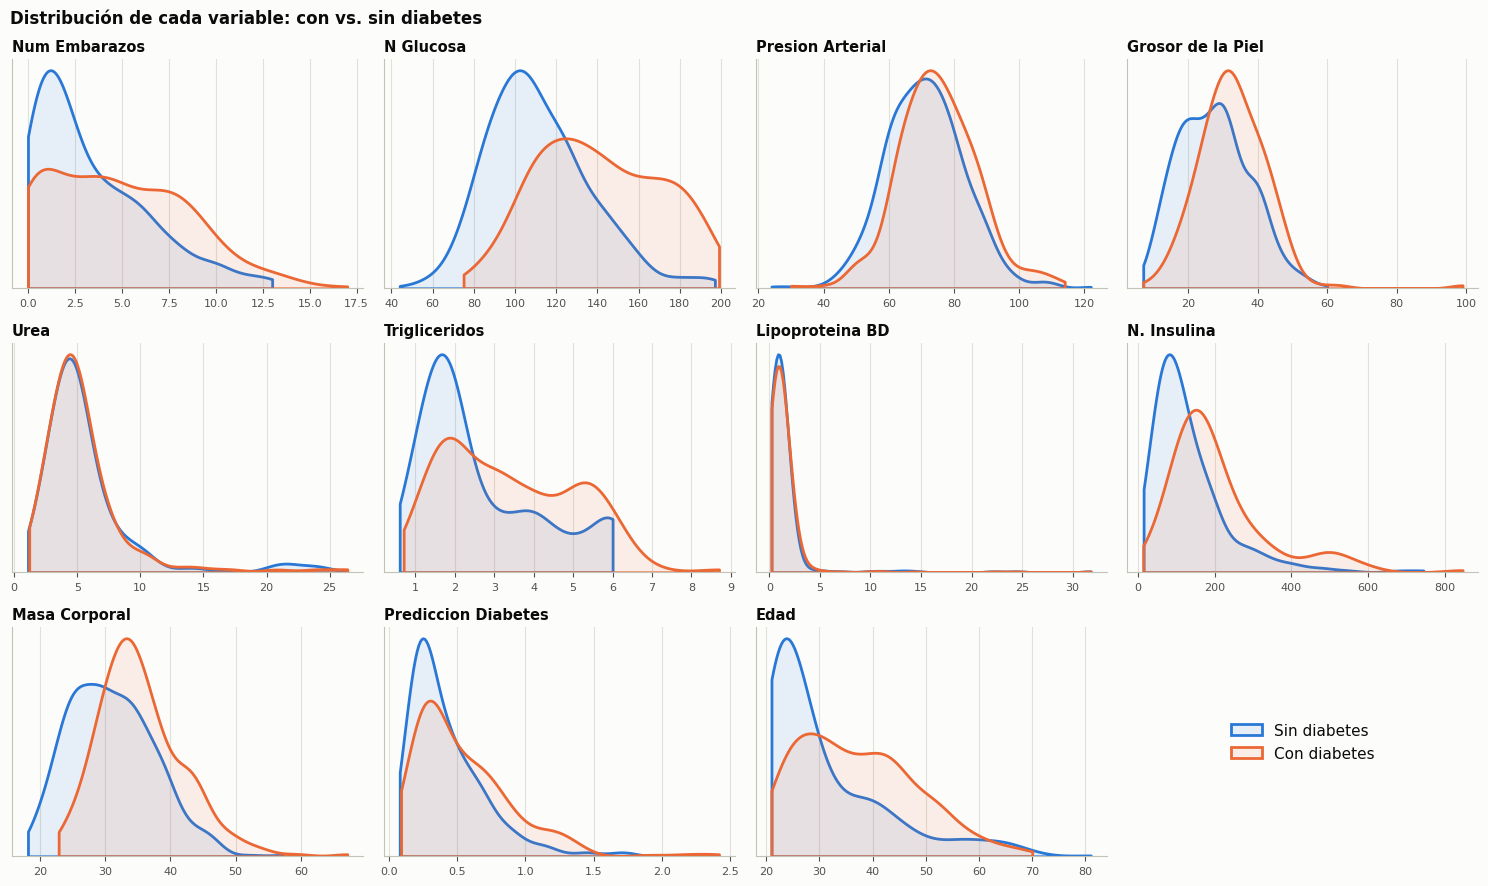

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for a, c in zip(axes.ravel(), PREDICTORAS):
    for k in (0, 1):
        v = dfp.loc[dfp[OBJETIVO] == k, c].dropna()
        sns.kdeplot(v, ax=a, color=COL_CLASE[k], lw=2, fill=True, alpha=.10, label=ETQ_CLASE[k], cut=0)
    a.set_title(c, fontsize=10.5); a.set_xlabel(''); a.set_ylabel(''); a.set_yticks([])
    a.tick_params(labelsize=8)
axes.ravel()[-1].axis('off')
h, l = axes.ravel()[0].get_legend_handles_labels()
axes.ravel()[-1].legend(h, l, loc='center', frameon=False, fontsize=11)
plt.suptitle('Distribución de cada variable: con vs. sin diabetes', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

### 3.3 ¿Qué variables separan a los dos grupos?
Para cada variable se calcula:
- **Mediana** en cada grupo.
- **Prueba de Mann-Whitney**: indica si la diferencia entre grupos es estadísticamente significativa (p < 0.05). No supone normalidad, lo que conviene porque varias variables están sesgadas.
- **AUC univariada**: probabilidad de que una persona con diabetes tenga un valor más alto que una sin diabetes. 0.5 = no separa; más lejos de 0.5 = separa mejor.
- **% faltante** después de convertir los ceros imposibles.

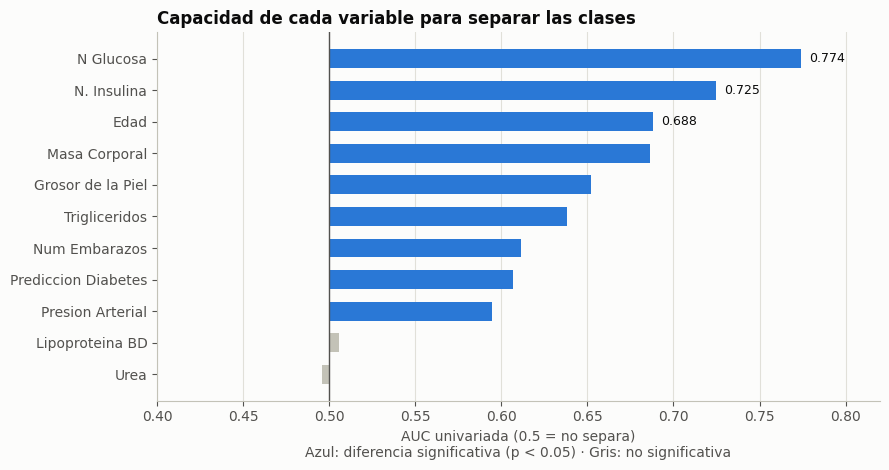

,Mediana con diabetes,Mediana sin diabetes,p-valor (Mann-Whitney),AUC univariada,% faltante
Variable,,,,,
N Glucosa,139.00,108.00,1.19e-38,0.774,0.7
N. Insulina,168.00,105.00,5.24e-14,0.725,48.9
Edad,36.00,27.00,3.38e-19,0.688,0.0
Masa Corporal,34.30,30.30,1.04e-18,0.686,1.3
Grosor de la Piel,32.00,27.00,1.69e-09,0.652,29.7
Trigliceridos,3.00,2.00,4.31e-11,0.638,0.0
Num Embarazos,4.00,2.00,9.00e-08,0.612,0.0
Prediccion Diabetes,0.44,0.34,3.73e-07,0.607,0.0
Presion Arterial,74.00,70.00,1.05e-05,0.595,4.6


In [ ]:
filas = []
for c in PREDICTORAS:
    a = dfp.loc[dfp[OBJETIVO] == 1, c].dropna(); b = dfp.loc[dfp[OBJETIVO] == 0, c].dropna()
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    filas.append({'Variable': c, 'Mediana con diabetes': a.median(), 'Mediana sin diabetes': b.median(),
                  'p-valor (Mann-Whitney)': p, 'AUC univariada': u / (len(a) * len(b)),
                  '% faltante': dfp[c].isna().mean() * 100})
tab_eda = pd.DataFrame(filas).set_index('Variable')
tab_eda['Separación'] = (tab_eda['AUC univariada'] - .5).abs()
tab_eda = tab_eda.sort_values('Separación', ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.8))
orden = tab_eda.sort_values('Separación')
col = [AZUL if p < .05 else '#c3c2b7' for p in orden['p-valor (Mann-Whitney)']]
ax.barh(orden.index, orden['AUC univariada'] - .5, left=.5, color=col, height=.6)
ax.axvline(.5, color='#52514e', lw=1)
for y_, v in zip(orden.index[-3:], orden['AUC univariada'].iloc[-3:]):
    ax.text(v + .005, y_, f'{v:.3f}', va='center', fontsize=9)
ax.set_xlim(.4, .82); ax.set_xlabel('AUC univariada (0.5 = no separa)\nAzul: diferencia significativa (p < 0.05) · Gris: no significativa')
ax.set_title('Capacidad de cada variable para separar las clases'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
display(tab_eda.drop(columns='Separación').style.format({'p-valor (Mann-Whitney)': '{:.2e}', 'AUC univariada': '{:.3f}',
        '% faltante': '{:.1f}', 'Mediana con diabetes': '{:.2f}', 'Mediana sin diabetes': '{:.2f}'}))

### 3.4 Correlaciones
El mapa incluye a `Tiene Diabetes` en la última fila para ver la relación de cada variable con el objetivo, y la correlación entre predictoras para detectar redundancia (dos variables que miden casi lo mismo). Se usa Spearman porque varias variables están sesgadas.

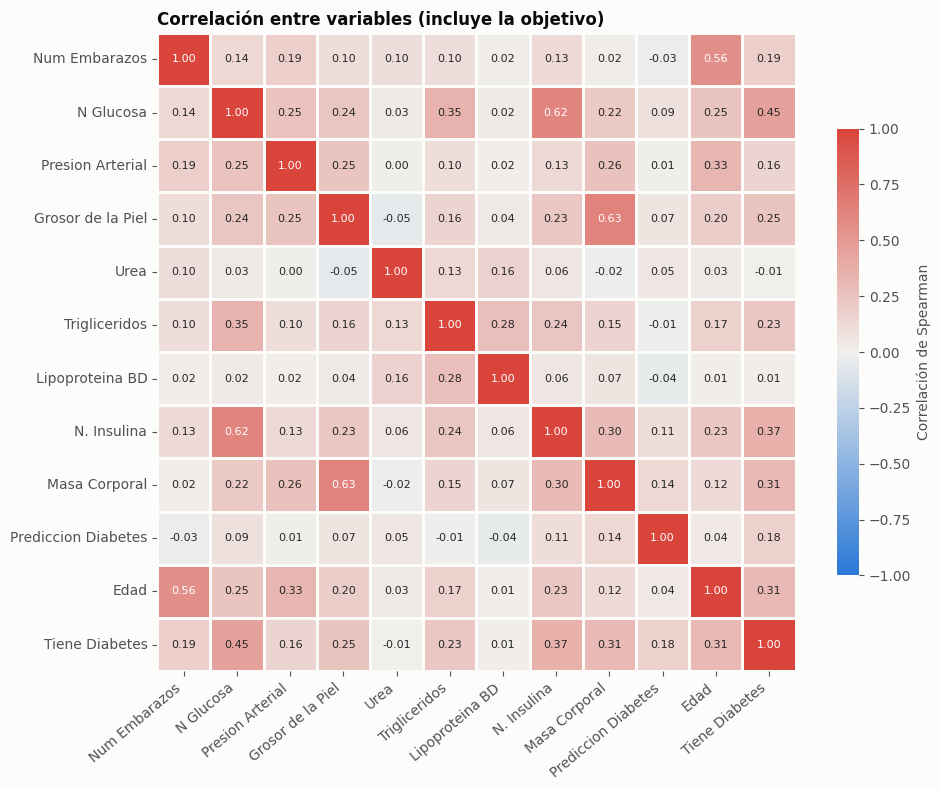

Pares de predictoras más correlacionados:


,,|rho|
Grosor de la Piel,Masa Corporal,0.6307
N Glucosa,N. Insulina,0.6206
Num Embarazos,Edad,0.5613
N Glucosa,Trigliceridos,0.3493


In [ ]:
cm = dfp[PREDICTORAS + [OBJETIVO]].corr(method='spearman')
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, cmap=DIV, vmin=-1, vmax=1, center=0, annot=True, fmt='.2f', annot_kws={'size': 8},
            linewidths=2, linecolor='#fcfcfb', square=True, cbar_kws={'shrink': .7, 'label': 'Correlación de Spearman'}, ax=ax)
ax.set_title('Correlación entre variables (incluye la objetivo)'); ax.grid(False)
plt.xticks(rotation=40, ha='right'); plt.tight_layout(); plt.show()
pares = cm.loc[PREDICTORAS, PREDICTORAS].where(np.triu(np.ones((len(PREDICTORAS),) * 2), k=1).astype(bool)).stack()
print('Pares de predictoras más correlacionados:')
display(pares.abs().sort_values(ascending=False).head(4).rename('|rho|').to_frame())

### 3.5 Decisión de variables
Criterio: se **conserva** una variable si (1) su diferencia entre grupos es significativa (p < 0.05) y (2) le faltan menos del 25% de los valores. Una variable sin diferencia entre grupos no aporta información; una con muchos faltantes obligaría a inventar (imputar) demasiados valores.

La decisión se comprueba con validación cruzada estratificada (5 pliegues × 10 repeticiones) comparando el AUC de los tres modelos con todas las variables contra las seleccionadas.

In [ ]:
tab_eda['Decisión'] = np.where(tab_eda['p-valor (Mann-Whitney)'] >= .05, 'descartar: no separa',
                      np.where(tab_eda['% faltante'] >= 25, 'descartar: muchos faltantes', 'usar'))
display(tab_eda[['AUC univariada', 'p-valor (Mann-Whitney)', '% faltante', 'Decisión']]
        .style.format({'AUC univariada': '{:.3f}', 'p-valor (Mann-Whitney)': '{:.2e}', '% faltante': '{:.1f}'}))
VARIABLES = [c for c in PREDICTORAS if tab_eda.loc[c, 'Decisión'] == 'usar']
print(f'Variables seleccionadas ({len(VARIABLES)}): {VARIABLES}')

def pipeline(modelo):
    return Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler()), ('modelo', modelo)])

def modelos():
    return {'Regresión Logística': LogisticRegression(max_iter=1000),
            'Random Forest': RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
            'Naive Bayes': GaussianNB()}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
comp = []
for nombre_set, cols in [('Todas (11)', PREDICTORAS), (f'Seleccionadas ({len(VARIABLES)})', VARIABLES)]:
    fila = {'Conjunto': nombre_set}
    for nom, m in modelos().items():
        fila[f'AUC {nom}'] = cross_validate(pipeline(m), dfp[cols], dfp[OBJETIVO], cv=cv, scoring='roc_auc')['test_score'].mean()
    comp.append(fila)
comp = pd.DataFrame(comp).set_index('Conjunto')
display(comp)
print('Cambio de AUC al usar solo las seleccionadas: ' + ', '.join(f'{c[4:]} {d:+.3f}' for c, d in (comp.iloc[1] - comp.iloc[0]).items()))

,AUC univariada,p-valor (Mann-Whitney),% faltante,Decisión
Variable,,,,
N Glucosa,0.774,1.19e-38,0.7,usar
N. Insulina,0.725,5.24e-14,48.9,descartar: muchos faltantes
Edad,0.688,3.38e-19,0.0,usar
Masa Corporal,0.686,1.04e-18,1.3,usar
Grosor de la Piel,0.652,1.69e-09,29.7,descartar: muchos faltantes
Trigliceridos,0.638,4.31e-11,0.0,usar
Num Embarazos,0.612,9.00e-08,0.0,usar
Prediccion Diabetes,0.607,3.73e-07,0.0,usar
Presion Arterial,0.595,1.05e-05,4.6,usar


Variables seleccionadas (7): ['Num Embarazos', 'N Glucosa', 'Presion Arterial', 'Trigliceridos', 'Masa Corporal', 'Prediccion Diabetes', 'Edad']


,AUC Regresión Logística,AUC Random Forest,AUC Naive Bayes
Conjunto,,,
Todas (11),0.8225,0.8398,0.7827
Seleccionadas (7),0.8257,0.8338,0.8118


Cambio de AUC al usar solo las seleccionadas: Regresión Logística +0.003, Random Forest -0.006, Naive Bayes +0.029


**Decisión.** Se usan las variables marcadas como "usar". `Urea` y `Lipoproteina BD` no muestran diferencia entre personas con y sin diabetes; `Grosor de la Piel` y `N. Insulina` sí la muestran, pero les falta una parte importante de los registros (cerca de 30% y 49%), por lo que imputarlas metería información inventada. La validación cruzada confirma que quitarlas no empeora el desempeño de forma relevante, y el modelo queda más simple y fácil de explicar.

## 4. Split de los datos (70% entrenamiento, 30% prueba)

La partición es **aleatoria** y **estratificada** (`stratify=y`) para que ambos conjuntos conserven la proporción de personas con diabetes; `random_state=42` la hace reproducible. Cada modelo es un `Pipeline` que imputa los faltantes con la mediana y estandariza, **ajustándose solo con entrenamiento**, para que la prueba no influya en el modelo.

In [ ]:
X = dfp[VARIABLES]
y = dfp[OBJETIVO]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
print(f'Entrenamiento: {len(X_train)} personas ({y_train.mean() * 100:.1f}% con diabetes)')
print(f'Prueba:        {len(X_test)} personas ({y_test.mean() * 100:.1f}% con diabetes)')

resultados = {}   # aquí se guardan predicciones y probabilidades de cada modelo

def evaluar(nombre, pipe):
    pred = pipe.predict(X_test); prob = pipe.predict_proba(X_test)[:, 1]
    vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()
    resultados[nombre] = {'pipe': pipe, 'pred': pred, 'prob': prob}
    m = {'Exactitud': accuracy_score(y_test, pred), 'Precisión': precision_score(y_test, pred),
         'Sensibilidad (recall)': recall_score(y_test, pred), 'Especificidad': vn / (vn + fp),
         'F1': f1_score(y_test, pred), 'AUC ROC': roc_auc_score(y_test, prob),
         'Exactitud entrenamiento': accuracy_score(y_train, pipe.predict(X_train))}
    print(f'{nombre} -> ' + ' | '.join(f'{k}: {v:.3f}' for k, v in m.items()))
    return m

Entrenamiento: 580 personas (35.2% con diabetes)
Prueba:        249 personas (35.3% con diabetes)


## 5. Algoritmo 1: Regresión Logística

Modelo lineal que estima la **probabilidad** de tener diabetes con la función logística. Es fácil de interpretar: cada coeficiente indica cómo cambia el riesgo al aumentar la variable.

**Métricas de cada variable:**
- **Coeficiente** (variables estandarizadas): efecto de subir una desviación estándar.
- **Odds ratio (OR)** = e^coeficiente: cuántas veces se multiplican los momios de tener diabetes al subir una desviación estándar. OR > 1 aumenta el riesgo, OR < 1 lo reduce.
- **p-valor** e **intervalo de confianza al 95%**: si el intervalo del OR no incluye 1 (p < 0.05), la variable es significativa.

Regresión Logística -> Exactitud: 0.739 | Precisión: 0.672 | Sensibilidad (recall): 0.511 | Especificidad: 0.863 | F1: 0.581 | AUC ROC: 0.801 | Exactitud entrenamiento: 0.769


,Coeficiente,Odds ratio,OR IC 2.5%,OR IC 97.5%,p-valor,Significativa
N Glucosa,+0.928,2.53,1.98,3.23,0.0000,sí
Masa Corporal,+0.703,2.02,1.60,2.55,0.0000,sí
Edad,+0.388,1.47,1.16,1.88,0.0017,sí
Prediccion Diabetes,+0.331,1.39,1.12,1.73,0.0028,sí
Num Embarazos,+0.294,1.34,1.06,1.70,0.0160,sí
Presion Arterial,-0.194,0.82,0.66,1.04,0.0963,no
Trigliceridos,+0.173,1.19,0.96,1.48,0.1182,no


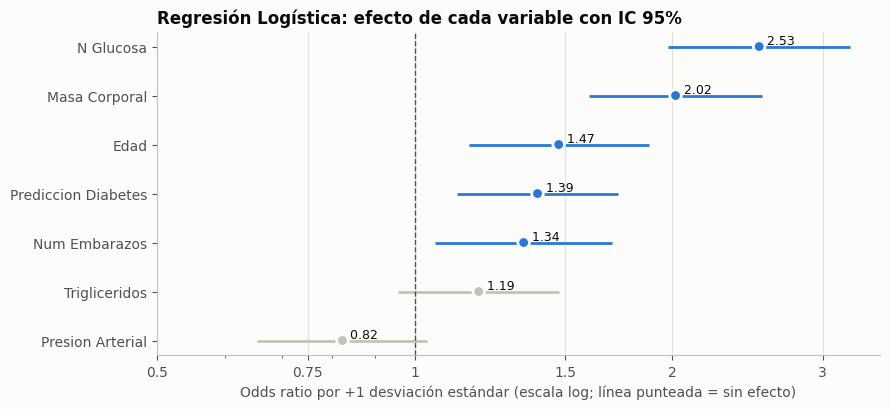

Azul = significativa (p < 0.05); gris = no significativa.


In [ ]:
pipe_lr = pipeline(LogisticRegression(max_iter=1000)).fit(X_train, y_train)
met_lr = evaluar('Regresión Logística', pipe_lr)

# Mismos datos que ve el modelo (imputados y estandarizados) para obtener p-valores con statsmodels
Xtr_s = pd.DataFrame(pipe_lr[:-1].transform(X_train), columns=VARIABLES, index=X_train.index)
logit = sm.Logit(y_train, sm.add_constant(Xtr_s)).fit(disp=0)
ic = logit.conf_int()
tab_lr = pd.DataFrame({'Coeficiente': logit.params, 'Odds ratio': np.exp(logit.params),
                       'OR IC 2.5%': np.exp(ic[0]), 'OR IC 97.5%': np.exp(ic[1]), 'p-valor': logit.pvalues}).drop('const')
tab_lr['Significativa'] = np.where(tab_lr['p-valor'] < .05, 'sí', 'no')
tab_lr = tab_lr.reindex(tab_lr['Coeficiente'].abs().sort_values(ascending=False).index)
display(tab_lr.style.format({'Coeficiente': '{:+.3f}', 'Odds ratio': '{:.2f}', 'OR IC 2.5%': '{:.2f}',
                             'OR IC 97.5%': '{:.2f}', 'p-valor': '{:.4f}'}))

o = tab_lr.sort_values('Odds ratio')
fig, ax = plt.subplots(figsize=(9, 4.2))
col = [AZUL if s == 'sí' else '#c3c2b7' for s in o['Significativa']]
ax.hlines(o.index, o['OR IC 2.5%'], o['OR IC 97.5%'], color=col, lw=2)
ax.scatter(o['Odds ratio'], o.index, color=col, s=70, zorder=3, edgecolor='#fcfcfb', linewidth=2)
ax.axvline(1, color='#52514e', lw=1, ls='--'); ax.set_xscale('log'); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xticks([.5, .75, 1, 1.5, 2, 3]); ax.set_xticklabels(['0.5', '0.75', '1', '1.5', '2', '3'])
for yy, v in zip(o.index, o['Odds ratio']):
    ax.text(v, yy, f'  {v:.2f}', va='bottom', fontsize=9)
ax.set_xlabel('Odds ratio por +1 desviación estándar (escala log; línea punteada = sin efecto)')
ax.set_title('Regresión Logística: efecto de cada variable con IC 95%'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
print('Azul = significativa (p < 0.05); gris = no significativa.')

## 6. Algoritmo 2: Random Forest

Ensamble de 300 árboles de decisión entrenados con muestras aleatorias; cada persona se clasifica por votación. Reduce el sobreajuste de un árbol individual y captura relaciones no lineales (por ejemplo, umbrales de glucosa). Es normal que acierte casi el 100% en entrenamiento porque sus árboles crecen sin límite; lo que importa es su desempeño en prueba y en validación cruzada.

**Métricas de cada variable:**
- **Importancia por impureza** (`feature_importances_`): cuánto reduce cada variable la mezcla de clases en los nodos (suma 1).
- **Importancia por permutación**: cuánto **cae el AUC en el conjunto de prueba** al revolver al azar los valores de esa variable. Es más confiable porque se mide con datos no vistos. No indica dirección del efecto.

Random Forest -> Exactitud: 0.759 | Precisión: 0.679 | Sensibilidad (recall): 0.602 | Especificidad: 0.845 | F1: 0.639 | AUC ROC: 0.802 | Exactitud entrenamiento: 1.000


,Importancia (impureza),Caída de AUC (permutación),Desv.
N Glucosa,0.2506,0.1487,0.0235
Masa Corporal,0.1766,0.0527,0.0160
Edad,0.1631,0.0307,0.0206
Prediccion Diabetes,0.1379,0.0190,0.0079
Trigliceridos,0.1083,0.0077,0.0081
Presion Arterial,0.0799,0.0004,0.0039
Num Embarazos,0.0837,-0.0084,0.0087


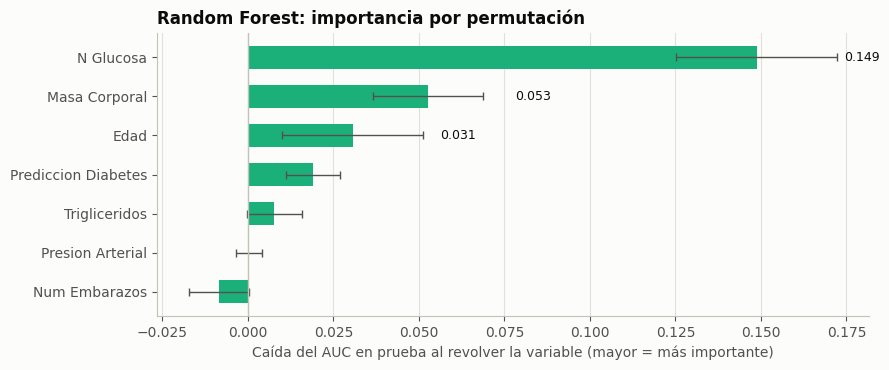

In [ ]:
pipe_rf = pipeline(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)).fit(X_train, y_train)
met_rf = evaluar('Random Forest', pipe_rf)

def perm(pipe):
    r = permutation_importance(pipe, X_test, y_test, scoring='roc_auc', n_repeats=30, random_state=42, n_jobs=-1)
    return pd.DataFrame({'Caída de AUC (permutación)': r.importances_mean, 'Desv.': r.importances_std}, index=VARIABLES)

tab_rf = perm(pipe_rf)
tab_rf.insert(0, 'Importancia (impureza)', pipe_rf[-1].feature_importances_)
tab_rf = tab_rf.sort_values('Caída de AUC (permutación)', ascending=False)
display(tab_rf)

def grafica_perm(tab, color, titulo):
    t = tab.sort_values('Caída de AUC (permutación)')
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.barh(t.index, t['Caída de AUC (permutación)'], xerr=t['Desv.'], color=color, height=.6,
            error_kw=dict(ecolor='#52514e', lw=1, capsize=3))
    ax.axvline(0, color='#c3c2b7', lw=1)
    for yy, v in zip(t.index[-3:], t['Caída de AUC (permutación)'].iloc[-3:]):
        ax.text(v + t['Desv.'].max() + .002, yy, f'{v:.3f}', va='center', fontsize=9)
    ax.set_xlabel('Caída del AUC en prueba al revolver la variable (mayor = más importante)')
    ax.set_title(titulo); ax.grid(axis='y', visible=False); plt.tight_layout(); plt.show()

grafica_perm(tab_rf, AQUA, 'Random Forest: importancia por permutación')

## 7. Algoritmo 3: Naive Bayes (Gaussiano)

Clasificador probabilístico basado en el teorema de Bayes. Supone que, dentro de cada clase, cada variable sigue una distribución normal y que las variables son independientes entre sí. Es rápido y simple, pero esas suposiciones rara vez se cumplen del todo (por ejemplo, edad y número de embarazos están relacionadas).

**Métricas de cada variable:** Naive Bayes no tiene coeficientes, así que se usa la **importancia por permutación** (caída de AUC en prueba) y la **media de cada variable por clase** que aprendió el modelo (en unidades estandarizadas): cuanto más se separan las medias, más pesa la variable.

Naive Bayes -> Exactitud: 0.747 | Precisión: 0.662 | Sensibilidad (recall): 0.580 | Especificidad: 0.839 | F1: 0.618 | AUC ROC: 0.779 | Exactitud entrenamiento: 0.759


,Media sin diabetes (z),Media con diabetes (z),Caída de AUC (permutación),Desv.,Diferencia de medias (z)
N Glucosa,-0.3445,0.6350,0.1129,0.0206,0.9795
Masa Corporal,-0.2336,0.4305,0.0295,0.0111,0.6640
Prediccion Diabetes,-0.1425,0.2627,0.0163,0.0069,0.4052
Edad,-0.2049,0.3777,0.0076,0.0113,0.5826
Num Embarazos,-0.1681,0.3098,0.0075,0.0111,0.4778
Trigliceridos,-0.1774,0.3270,0.0057,0.0100,0.5044
Presion Arterial,-0.0960,0.1769,-0.0005,0.0049,0.2729


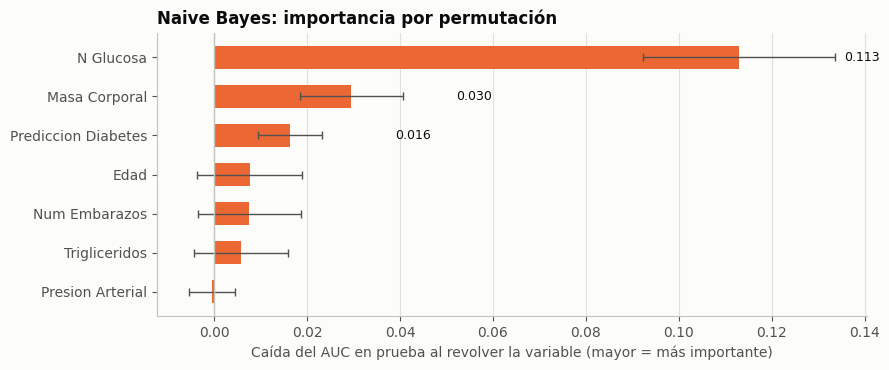

In [ ]:
pipe_nb = pipeline(GaussianNB()).fit(X_train, y_train)
met_nb = evaluar('Naive Bayes', pipe_nb)

tab_nb = perm(pipe_nb)
medias = pd.DataFrame(pipe_nb[-1].theta_.T, index=VARIABLES, columns=['Media sin diabetes (z)', 'Media con diabetes (z)'])
tab_nb = medias.join(tab_nb)
tab_nb['Diferencia de medias (z)'] = tab_nb['Media con diabetes (z)'] - tab_nb['Media sin diabetes (z)']
tab_nb = tab_nb.sort_values('Caída de AUC (permutación)', ascending=False)
display(tab_nb)
grafica_perm(tab_nb, NARANJA, 'Naive Bayes: importancia por permutación')

## 8. Variables independientes que más inciden en la variable objetivo

### 8.1 Comparación entre algoritmos
Cada modelo mide la importancia en una escala distinta, así que se normaliza cada una a 100%: |coeficiente| para la Regresión Logística y caída de AUC por permutación para Random Forest y Naive Bayes. Una variable con valores altos en las tres columnas incide en la diabetes sin importar el algoritmo. Cuando dos variables comparten información (por ejemplo, `Edad` y `Num Embarazos`, con correlación de 0.56), un modelo puede darle casi todo el peso a una y casi nada a la otra; por eso conviene leer el promedio y no un solo modelo.

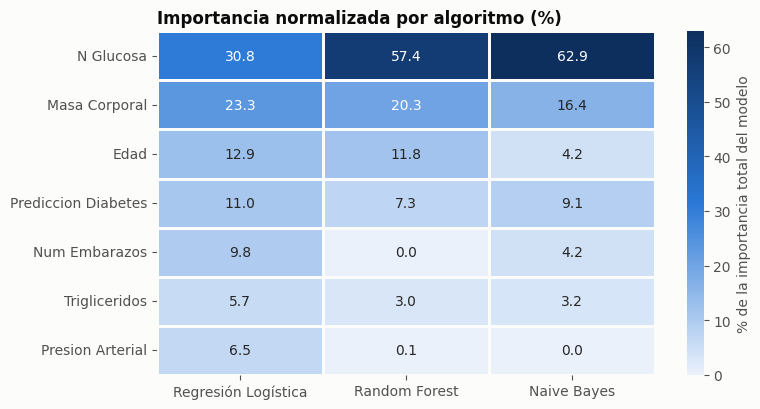

,Regresión Logística,Random Forest,Naive Bayes,Promedio
N Glucosa,30.8000,57.4000,62.9000,50.4000
Masa Corporal,23.3000,20.3000,16.4000,20.0000
Edad,12.9000,11.8000,4.2000,9.7000
Prediccion Diabetes,11.0000,7.3000,9.1000,9.1000
Num Embarazos,9.8000,0.0000,4.2000,4.6000
Trigliceridos,5.7000,3.0000,3.2000,4.0000
Presion Arterial,6.5000,0.1000,0.0000,2.2000


Variables que más inciden (promedio de los tres modelos): N Glucosa (50.4%), Masa Corporal (20.0%), Edad (9.7%)


In [ ]:
imp = pd.DataFrame({'Regresión Logística': tab_lr['Coeficiente'].abs(),
                    'Random Forest': tab_rf['Caída de AUC (permutación)'].clip(lower=0),
                    'Naive Bayes': tab_nb['Caída de AUC (permutación)'].clip(lower=0)})
imp = imp / imp.sum() * 100
imp['Promedio'] = imp.mean(axis=1)
imp = imp.sort_values('Promedio', ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.heatmap(imp.drop(columns='Promedio'), cmap=SEC, annot=True, fmt='.1f', linewidths=2, linecolor='#fcfcfb',
            cbar_kws={'label': '% de la importancia total del modelo'}, ax=ax)
ax.set_title('Importancia normalizada por algoritmo (%)'); ax.set_ylabel(''); ax.grid(False)
plt.tight_layout(); plt.show()
display(imp.round(1))
TOP = imp.index[:3].tolist()
print(f'Variables que más inciden (promedio de los tres modelos): ' +
      ', '.join(f'{v} ({imp.loc[v, "Promedio"]:.1f}%)' for v in TOP))

### 8.2 Métricas de cada variable significativa
Se reúnen en una tabla las métricas de cada variable que resultó significativa en la Regresión Logística (p < 0.05): su efecto (odds ratio), su significancia, la diferencia entre grupos observada en el EDA y su importancia en los otros dos modelos.

In [ ]:
sig = tab_lr[tab_lr['Significativa'] == 'sí'].index
tab_sig = pd.DataFrame({
    'Odds ratio (+1 DE)': tab_lr.loc[sig, 'Odds ratio'],
    'IC 95%': [f'{a:.2f} – {b:.2f}' for a, b in tab_lr.loc[sig, ['OR IC 2.5%', 'OR IC 97.5%']].values],
    'p-valor': tab_lr.loc[sig, 'p-valor'],
    'Mediana con diabetes': tab_eda.loc[sig, 'Mediana con diabetes'],
    'Mediana sin diabetes': tab_eda.loc[sig, 'Mediana sin diabetes'],
    'AUC univariada': tab_eda.loc[sig, 'AUC univariada'],
    'Permutación RF': tab_rf.loc[sig, 'Caída de AUC (permutación)'],
    'Permutación NB': tab_nb.loc[sig, 'Caída de AUC (permutación)'],
}).sort_values('Odds ratio (+1 DE)', ascending=False)
display(tab_sig.style.format({'Odds ratio (+1 DE)': '{:.2f}', 'p-valor': '{:.4f}', 'Mediana con diabetes': '{:.2f}',
                              'Mediana sin diabetes': '{:.2f}', 'AUC univariada': '{:.3f}',
                              'Permutación RF': '{:.3f}', 'Permutación NB': '{:.3f}'}))
for v in sig:
    sd = X_train[v].std()
    print(f'- {v}: subir {sd:.1f} unidades (1 DE) multiplica los momios de diabetes por {tab_lr.loc[v, "Odds ratio"]:.2f}')

,Odds ratio (+1 DE),IC 95%,p-valor,Mediana con diabetes,Mediana sin diabetes,AUC univariada,Permutación RF,Permutación NB
N Glucosa,2.53,1.98 – 3.23,0.0000,139.00,108.00,0.774,0.149,0.113
Masa Corporal,2.02,1.60 – 2.55,0.0000,34.30,30.30,0.686,0.053,0.030
Edad,1.47,1.16 – 1.88,0.0017,36.00,27.00,0.688,0.031,0.008
Prediccion Diabetes,1.39,1.12 – 1.73,0.0028,0.44,0.34,0.607,0.019,0.016
Num Embarazos,1.34,1.06 – 1.70,0.0160,4.00,2.00,0.612,-0.008,0.008


- N Glucosa: subir 30.9 unidades (1 DE) multiplica los momios de diabetes por 2.53
- Masa Corporal: subir 7.0 unidades (1 DE) multiplica los momios de diabetes por 2.02
- Edad: subir 11.9 unidades (1 DE) multiplica los momios de diabetes por 1.47
- Prediccion Diabetes: subir 0.3 unidades (1 DE) multiplica los momios de diabetes por 1.39
- Num Embarazos: subir 3.3 unidades (1 DE) multiplica los momios de diabetes por 1.34


## 9. Matriz de confusión: falsos positivos y falsos negativos

La matriz compara la clase real con la predicha en el conjunto de prueba:

| | Predicho: sin diabetes | Predicho: con diabetes |
|---|---|---|
| **Real: sin diabetes** | Verdadero negativo (VN) | **Falso positivo (FP)** |
| **Real: con diabetes** | **Falso negativo (FN)** | Verdadero positivo (VP) |

- **Falso positivo:** persona **sana** que el modelo marca como diabética. Costo: una prueba confirmatoria innecesaria y preocupación para el paciente.
- **Falso negativo:** persona **con diabetes** que el modelo marca como sana. Es el error **más grave** en este caso de negocio, porque la persona no se envía a diagnóstico y la enfermedad avanza sin tratamiento.

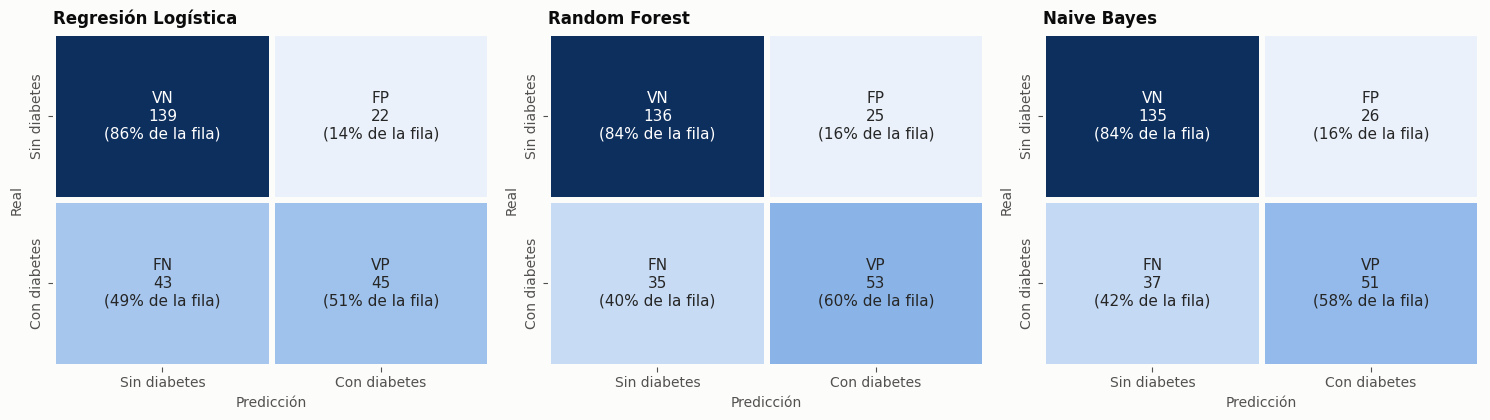

Regresión Logística: 22 falsos positivos (13.7% de las personas sanas fueron alarmadas sin necesidad) y 43 falsos negativos (48.9% de las personas con diabetes no fueron detectadas).
Random Forest: 25 falsos positivos (15.5% de las personas sanas fueron alarmadas sin necesidad) y 35 falsos negativos (39.8% de las personas con diabetes no fueron detectadas).
Naive Bayes: 26 falsos positivos (16.1% de las personas sanas fueron alarmadas sin necesidad) y 37 falsos negativos (42.0% de las personas con diabetes no fueron detectadas).


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for a, (nom, r) in zip(axes, resultados.items()):
    m = confusion_matrix(y_test, r['pred'])
    etq = np.array([['VN', 'FP'], ['FN', 'VP']])
    txt = np.array([[f'{etq[i, j]}\n{m[i, j]}\n({m[i, j] / m[i].sum() * 100:.0f}% de la fila)' for j in range(2)] for i in range(2)])
    sns.heatmap(m, annot=txt, fmt='', cmap=SEC, cbar=False, linewidths=3, linecolor='#fcfcfb', ax=a,
                annot_kws={'size': 11}, xticklabels=['Sin diabetes', 'Con diabetes'], yticklabels=['Sin diabetes', 'Con diabetes'])
    a.set_xlabel('Predicción'); a.set_ylabel('Real'); a.set_title(nom); a.grid(False)
plt.tight_layout(); plt.show()

for nom, r in resultados.items():
    vn, fp, fn, vp = confusion_matrix(y_test, r['pred']).ravel()
    print(f'{nom}: {fp} falsos positivos ({fp / (fp + vn) * 100:.1f}% de las personas sanas fueron alarmadas sin necesidad) y '
          f'{fn} falsos negativos ({fn / (fn + vp) * 100:.1f}% de las personas con diabetes no fueron detectadas).')

### 9.1 ¿Por qué se equivocan los modelos?
Se comparan las medianas de las variables más importantes en cada tipo de resultado del modelo con mejor AUC. Normalmente los falsos negativos son personas con diabetes pero con valores "de persona sana" (glucosa o masa corporal más bajas), y los falsos positivos son personas sanas con valores "de riesgo". Es decir, son casos en la frontera entre ambos grupos.

In [ ]:
MEJOR = max(resultados, key=lambda n: roc_auc_score(y_test, resultados[n]['prob']))
r = resultados[MEJOR]
tipo = np.select([(y_test == 1) & (r['pred'] == 1), (y_test == 0) & (r['pred'] == 0),
                  (y_test == 0) & (r['pred'] == 1), (y_test == 1) & (r['pred'] == 0)], ['VP', 'VN', 'FP', 'FN'], default='')
perfil = X_test.assign(Resultado=tipo).groupby('Resultado')[TOP + [v for v in VARIABLES if v not in TOP][:2]].median()
perfil = perfil.reindex(['VN', 'FP', 'FN', 'VP'])
perfil.insert(0, 'Personas', pd.Series(tipo).value_counts().reindex(perfil.index).values)
print(f'Modelo con mejor AUC en prueba: {MEJOR}. Medianas por tipo de resultado:')
display(perfil)

Modelo con mejor AUC en prueba: Random Forest. Medianas por tipo de resultado:


,Personas,N Glucosa,Masa Corporal,Edad,Num Embarazos,Presion Arterial
Resultado,,,,,,
VN,136,105.0000,30.1000,26.0000,2.0000,70.0000
FP,25,136.0000,35.2000,40.0000,5.0000,78.0000
FN,35,124.0000,32.6000,29.0000,3.0000,73.0000
VP,53,151.0000,36.6000,37.0000,5.0000,76.0000


## 10. Personas en los falsos positivos y falsos negativos

Se listan las personas mal clasificadas por el modelo con mejor AUC, con su probabilidad estimada de diabetes y sus valores en las variables más importantes. `Fila` es la posición en el archivo original (necesaria porque algunos IDs de `Persona` se repiten). Al final se indican las personas en las que **los tres modelos** se equivocan: son los casos más difíciles y los primeros que conviene revisar clínicamente.

In [ ]:
def personas(nom, cual):
    r = resultados[nom]
    mask = ((y_test == 0) & (r['pred'] == 1)) if cual == 'FP' else ((y_test == 1) & (r['pred'] == 0))
    t = df.loc[X_test.index[mask], ['Persona'] + VARIABLES + [OBJETIVO]].copy()
    t.insert(0, 'Fila', t.index)
    t.insert(2, 'Prob. diabetes', r['prob'][mask])
    return t.sort_values('Prob. diabetes', ascending=(cual == 'FN'))

fp_t, fn_t = personas(MEJOR, 'FP'), personas(MEJOR, 'FN')
print(f'{MEJOR} - FALSOS POSITIVOS: {len(fp_t)} personas sanas clasificadas con diabetes (ordenadas de mayor a menor probabilidad)')
display(fp_t.style.format({'Prob. diabetes': '{:.2f}'}).hide(axis='index'))
print(f'\n{MEJOR} - FALSOS NEGATIVOS: {len(fn_t)} personas con diabetes no detectadas (ordenadas de menor a mayor probabilidad)')
display(fn_t.style.format({'Prob. diabetes': '{:.2f}'}).hide(axis='index'))

# Coincidencias entre los tres modelos
fp_sets = {n: set(personas(n, 'FP')['Fila']) for n in resultados}
fn_sets = {n: set(personas(n, 'FN')['Fila']) for n in resultados}
fp_todos, fn_todos = set.intersection(*fp_sets.values()), set.intersection(*fn_sets.values())
fmt = lambda filas: ', '.join(f'{df.loc[f, "Persona"]} (fila {f})' for f in sorted(filas, key=lambda f: df.loc[f, 'Persona']))
print(f'\nFalsos positivos en los tres modelos: {len(fp_todos)} personas -> {fmt(fp_todos)}')
print(f'Falsos negativos en los tres modelos: {len(fn_todos)} personas -> {fmt(fn_todos)}')

# Archivo con todas las personas mal clasificadas por cada modelo
salida = pd.concat([personas(n, c).assign(Modelo=n, Error=c) for n in resultados for c in ('FP', 'FN')])
salida.to_csv('personas_falsos_positivos_negativos.csv', index=False)
print("Se guardó 'personas_falsos_positivos_negativos.csv' con los errores de los tres modelos.")

Random Forest - FALSOS POSITIVOS: 25 personas sanas clasificadas con diabetes (ordenadas de mayor a menor probabilidad)


Fila,Persona,Prob. diabetes,Num Embarazos,N Glucosa,Presion Arterial,Trigliceridos,Masa Corporal,Prediccion Diabetes,Edad,Tiene Diabetes
69,4970,0.86,0,173,78,2.000000,46.500000,1.159000,58,0
9,3700,0.82,8,196,76,5.000000,46.300000,1.096000,32,0
135,5090,0.79,6,154,74,3.000000,29.300000,0.839000,39,0
137,6790,0.79,9,154,78,3.000000,30.900000,0.164000,45,0
151,5910,0.76,12,151,70,5.500000,32.000000,0.391000,39,0
363,2560,0.72,10,122,68,1.100000,31.200000,0.258000,41,0
385,6670,0.67,1,120,80,5.300000,38.900000,1.162000,41,0
171,680,0.66,0,146,82,1.500000,40.500000,1.781000,44,0
148,3050,0.64,6,151,62,5.400000,35.500000,0.692000,28,0
174,2540,0.63,2,146,76,3.700000,38.200000,0.329000,29,0



Random Forest - FALSOS NEGATIVOS: 35 personas con diabetes no detectadas (ordenadas de menor a mayor probabilidad)


Fila,Persona,Prob. diabetes,Num Embarazos,N Glucosa,Presion Arterial,Trigliceridos,Masa Corporal,Prediccion Diabetes,Edad,Tiene Diabetes
703,480,0.02,2,90,68,1.900000,38.200000,0.503000,27,1
219,2520,0.04,3,139,54,1.300000,25.600000,0.402000,22,1
458,3310,0.04,3,112,74,2.800000,31.600000,0.197000,25,1
788,160,0.07,3,78,50,4.000000,31.000000,0.248000,26,1
483,7360,0.08,3,111,62,4.000000,28.400000,0.259000,22,1
301,3030,0.11,1,128,48,2.000000,40.500000,0.613000,24,1
406,5870,0.15,2,118,80,0.800000,42.900000,0.693000,21,1
564,4580,0.16,0,104,64,1.500000,33.600000,0.510000,22,1
373,6880,0.16,3,121,52,2.900000,36.000000,0.127000,25,1
303,5510,0.19,3,128,72,2.000000,32.400000,0.549000,27,1



Falsos positivos en los tres modelos: 13 personas -> 680 (fila 171), 770 (fila 494), 2140 (fila 571), 2210 (fila 164), 3050 (fila 148), 3700 (fila 9), 4800 (fila 189), 4970 (fila 69), 5090 (fila 135), 5910 (fila 151), 6670 (fila 385), 6790 (fila 137), 6940 (fila 245)
Falsos negativos en los tres modelos: 24 personas -> 160 (fila 788), 480 (fila 703), 800 (fila 603), 1260 (fila 338), 1990 (fila 218), 2520 (fila 219), 2970 (fila 393), 3030 (fila 301), 3060 (fila 177), 3310 (fila 458), 3320 (fila 341), 3790 (fila 262), 4100 (fila 665), 4160 (fila 431), 4580 (fila 564), 4860 (fila 556), 5220 (fila 224), 5450 (fila 266), 5510 (fila 303), 5870 (fila 406), 6690 (fila 782), 6880 (fila 373), 6930 (fila 335), 7360 (fila 483)
Se guardó 'personas_falsos_positivos_negativos.csv' con los errores de los tres modelos.


## 11. Métricas de evaluación de los algoritmos

### 11.1 Conjunto de prueba
- **Exactitud:** proporción de aciertos totales (engaña con clases desbalanceadas).
- **Precisión:** de los que el modelo marca con diabetes, cuántos la tienen (castiga los FP).
- **Sensibilidad (recall):** de los que tienen diabetes, cuántos detecta (castiga los FN; **la más importante para tamizaje**).
- **Especificidad:** de los sanos, cuántos reconoce como sanos.
- **F1:** balance entre precisión y sensibilidad.
- **AUC ROC:** capacidad de ordenar a los enfermos por encima de los sanos sin importar el umbral (0.5 = azar, 1 = perfecto).

,Exactitud,Precisión,Sensibilidad (recall),Especificidad,F1,AUC ROC,Exactitud entrenamiento
Random Forest,0.759,0.679,0.602,0.845,0.639,0.802,1.000
Regresión Logística,0.739,0.672,0.511,0.863,0.581,0.801,0.769
Naive Bayes,0.747,0.662,0.580,0.839,0.618,0.779,0.759


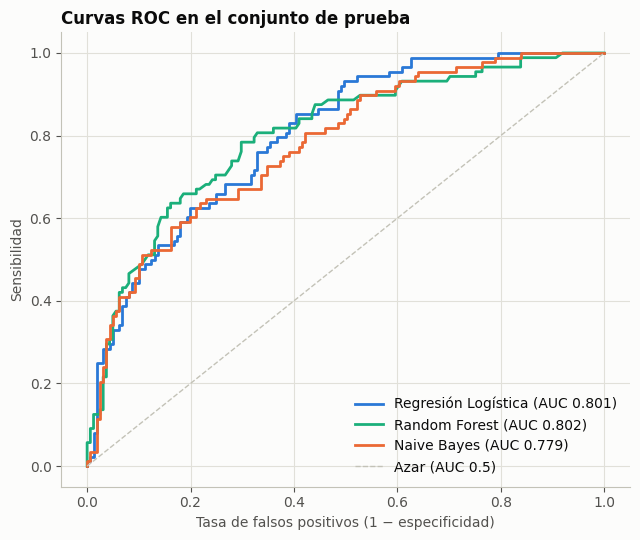

--- Regresión Logística ---
              precision    recall  f1-score   support

Sin diabetes      0.764     0.863     0.810       161
Con diabetes      0.672     0.511     0.581        88

    accuracy                          0.739       249
   macro avg      0.718     0.687     0.696       249
weighted avg      0.731     0.739     0.729       249

--- Random Forest ---
              precision    recall  f1-score   support

Sin diabetes      0.795     0.845     0.819       161
Con diabetes      0.679     0.602     0.639        88

    accuracy                          0.759       249
   macro avg      0.737     0.723     0.729       249
weighted avg      0.754     0.759     0.755       249

--- Naive Bayes ---
              precision    recall  f1-score   support

Sin diabetes      0.785     0.839     0.811       161
Con diabetes      0.662     0.580     0.618        88

    accuracy                          0.747       249
   macro avg      0.724     0.709     0.714       249
weig

In [ ]:
tabla_metricas = pd.DataFrame({'Regresión Logística': met_lr, 'Random Forest': met_rf, 'Naive Bayes': met_nb}).T
tabla_metricas = tabla_metricas.sort_values('AUC ROC', ascending=False)
display(tabla_metricas.style.format('{:.3f}').highlight_max(axis=0, color='#e7f1fb', subset=tabla_metricas.columns[:-1]))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for nom, r in resultados.items():
    fpr, tpr, _ = roc_curve(y_test, r['prob'])
    ax.plot(fpr, tpr, color=COL_MODELO[nom], lw=2, label=f'{nom} (AUC {roc_auc_score(y_test, r["prob"]):.3f})')
ax.plot([0, 1], [0, 1], color='#c3c2b7', lw=1, ls='--', label='Azar (AUC 0.5)')
ax.set_xlabel('Tasa de falsos positivos (1 − especificidad)'); ax.set_ylabel('Sensibilidad')
ax.set_title('Curvas ROC en el conjunto de prueba'); ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

for nom, r in resultados.items():
    print(f'--- {nom} ---')
    print(classification_report(y_test, r['pred'], target_names=['Sin diabetes', 'Con diabetes'], digits=3))

### 11.2 Validación cruzada estratificada (5 pliegues × 10 repeticiones)
Un solo split de prueba puede favorecer a un modelo por azar. Aquí cada modelo se evalúa 50 veces con particiones distintas y se reporta media ± desviación estándar. Si la diferencia entre dos modelos es menor que la desviación, no es concluyente.

,AUC,Exactitud,Sensibilidad,Precisión,F1,AUC (desv.)
Algoritmo,,,,,,
Random Forest,0.834,0.772,0.608,0.707,0.652,0.025
Regresión Logística,0.826,0.758,0.550,0.702,0.615,0.025
Naive Bayes,0.812,0.742,0.597,0.647,0.619,0.024


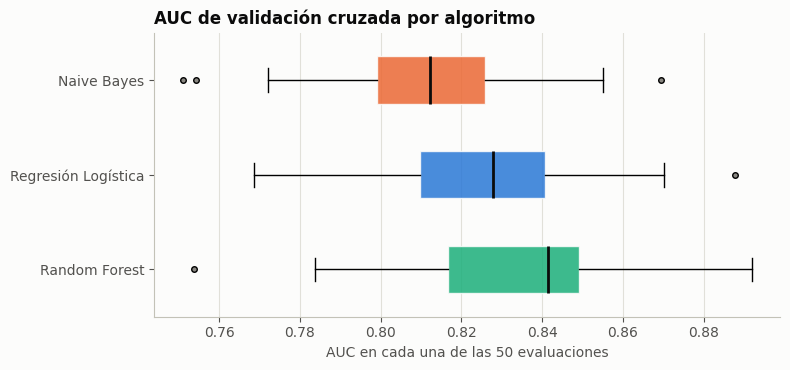

In [ ]:
filas, cv_raw = [], {}
for nom, m in modelos().items():
    s = cross_validate(pipeline(m), X, y, cv=cv, scoring=['roc_auc', 'accuracy', 'recall', 'precision', 'f1'], n_jobs=1)
    cv_raw[nom] = s
    filas.append({'Algoritmo': nom, **{f'{k} (media)': s[f'test_{k}'].mean() for k in ['roc_auc', 'accuracy', 'recall', 'precision', 'f1']},
                  'AUC (desv.)': s['test_roc_auc'].std()})
tabla_cv = pd.DataFrame(filas).set_index('Algoritmo').sort_values('roc_auc (media)', ascending=False)
tabla_cv.columns = ['AUC', 'Exactitud', 'Sensibilidad', 'Precisión', 'F1', 'AUC (desv.)']
display(tabla_cv.style.format('{:.3f}'))

fig, ax = plt.subplots(figsize=(8, 3.8))
bp = ax.boxplot([cv_raw[n]['test_roc_auc'] for n in tabla_cv.index], patch_artist=True, widths=.5, vert=False,
                medianprops=dict(color='#0b0b0b', lw=2), flierprops=dict(marker='o', markersize=4, markerfacecolor=GRIS))
for p, n in zip(bp['boxes'], tabla_cv.index):
    p.set_facecolor(COL_MODELO[n]); p.set_alpha(.85); p.set_edgecolor('#fcfcfb')
ax.set_yticklabels(tabla_cv.index); ax.set_xlabel('AUC en cada una de las 50 evaluaciones')
ax.set_title('AUC de validación cruzada por algoritmo'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
RECOMENDADO = tabla_cv.index[0]

### 11.3 Ajuste del umbral para reducir falsos negativos
Por defecto se clasifica "con diabetes" si la probabilidad es ≥ 0.5. En tamizaje conviene bajar ese umbral para detectar más casos, aceptando más falsos positivos. El umbral se elige **solo con el conjunto de entrenamiento** (probabilidades fuera de pliegue) como el más alto que logra al menos 80% de sensibilidad, y después se aplica una sola vez a la prueba.

In [ ]:
META = 0.80
pipe_rec = {'Regresión Logística': pipe_lr, 'Random Forest': pipe_rf, 'Naive Bayes': pipe_nb}[RECOMENDADO]
p_oof = cross_val_predict(pipeline(modelos()[RECOMENDADO]), X_train, y_train, method='predict_proba',
                          cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))[:, 1]
umbrales = np.round(np.arange(0.10, 0.51, 0.01), 2)
sens_tr = [recall_score(y_train, (p_oof >= u).astype(int)) for u in umbrales]
UMBRAL = max([u for u, s in zip(umbrales, sens_tr) if s >= META], default=0.5)

prob_te = resultados[RECOMENDADO]['prob']
comp_u = []
for u in [0.5, UMBRAL]:
    pr = (prob_te >= u).astype(int); vn, fp, fn, vp = confusion_matrix(y_test, pr).ravel()
    comp_u.append({'Umbral': u, 'Sensibilidad': vp / (vp + fn), 'Especificidad': vn / (vn + fp),
                   'Precisión': precision_score(y_test, pr), 'Falsos negativos': fn, 'Falsos positivos': fp})
comp_u = pd.DataFrame(comp_u).set_index('Umbral')
print(f'Modelo recomendado (mejor AUC en validación cruzada): {RECOMENDADO}. Umbral elegido con entrenamiento: {UMBRAL:.2f}')
display(comp_u.style.format({'Sensibilidad': '{:.3f}', 'Especificidad': '{:.3f}', 'Precisión': '{:.3f}'}))

Modelo recomendado (mejor AUC en validación cruzada): Random Forest. Umbral elegido con entrenamiento: 0.34


,Sensibilidad,Especificidad,Precisión,Falsos negativos,Falsos positivos
Umbral,,,,,
0.500000,0.602,0.845,0.679,35,25
0.340000,0.795,0.677,0.574,18,52


## 12. Conclusiones desde el punto de vista de negocio

El resumen siguiente se calcula con los resultados del cuaderno, de modo que se mantiene coherente con las tablas.

In [ ]:
cvr = tabla_cv.loc[RECOMENDADO]
u0, u1 = comp_u.iloc[0], comp_u.iloc[1]
print('CONCLUSIONES\n')
print('1. Características que determinan la diabetes')
print('   Las variables que más inciden (promedio de los tres algoritmos) son ' +
      ', '.join(f'{v} ({imp.loc[v, "Promedio"]:.0f}%)' for v in TOP) + '.')
for v in tab_sig.index[:3]:
    print(f'   - {v}: OR {tab_lr.loc[v, "Odds ratio"]:.2f} por desviación estándar; mediana {tab_eda.loc[v, "Mediana con diabetes"]:.1f} '
          f'con diabetes vs. {tab_eda.loc[v, "Mediana sin diabetes"]:.1f} sin diabetes.')
print('\n2. Modelo recomendado')
print(f'   {RECOMENDADO}: AUC {cvr["AUC"]:.3f} ± {cvr["AUC (desv.)"]:.3f} en validación cruzada '
      f'(exactitud {cvr["Exactitud"]:.3f}, sensibilidad {cvr["Sensibilidad"]:.3f}).')
dif = tabla_cv['AUC'].iloc[0] - tabla_cv['AUC'].iloc[1]
print(f'   Diferencia con {tabla_cv.index[1]}: {dif:.3f} de AUC ' +
      ('(menor que la variabilidad entre particiones: rinden parecido).' if dif < tabla_cv['AUC (desv.)'].iloc[:2].max()
       else '(mayor que la variabilidad entre particiones).'))
print('\n3. Errores')
print(f'   Con umbral 0.5 el modelo deja sin detectar a {int(u0["Falsos negativos"])} de {int(y_test.sum())} personas con diabetes '
      f'en la prueba (sensibilidad {u0["Sensibilidad"]:.2f}) y alarma a {int(u0["Falsos positivos"])} personas sanas.')
print(f'   Con umbral {UMBRAL:.2f} los falsos negativos bajan a {int(u1["Falsos negativos"])} (sensibilidad {u1["Sensibilidad"]:.2f}) '
      f'a cambio de {int(u1["Falsos positivos"])} falsos positivos.')

CONCLUSIONES

1. Características que determinan la diabetes
   Las variables que más inciden (promedio de los tres algoritmos) son N Glucosa (50%), Masa Corporal (20%), Edad (10%).
   - N Glucosa: OR 2.53 por desviación estándar; mediana 139.0 con diabetes vs. 108.0 sin diabetes.
   - Masa Corporal: OR 2.02 por desviación estándar; mediana 34.3 con diabetes vs. 30.3 sin diabetes.
   - Edad: OR 1.47 por desviación estándar; mediana 36.0 con diabetes vs. 27.0 sin diabetes.

2. Modelo recomendado
   Random Forest: AUC 0.834 ± 0.025 en validación cruzada (exactitud 0.772, sensibilidad 0.608).
   Diferencia con Regresión Logística: 0.008 de AUC (menor que la variabilidad entre particiones: rinden parecido).

3. Errores
   Con umbral 0.5 el modelo deja sin detectar a 35 de 88 personas con diabetes en la prueba (sensibilidad 0.60) y alarma a 25 personas sanas.
   Con umbral 0.34 los falsos negativos bajan a 18 (sensibilidad 0.80) a cambio de 52 falsos positivos.


### Interpretación para el negocio
- **Qué vigilar.** La glucosa es el indicador que más separa a las personas con diabetes; le siguen la masa corporal y la edad. Una campaña de prevención debería priorizar a personas con glucosa elevada y sobrepeso, sobre todo a partir de la mediana de edad del grupo con diabetes.
- **Cómo usar el modelo.** Como herramienta de **tamizaje**: ordena a las personas por probabilidad y envía a prueba confirmatoria a quienes superen el umbral. Para este uso conviene el umbral reducido, porque un falso negativo (un diabético sin detectar) cuesta más que un falso positivo (una prueba de laboratorio adicional).
- **Casos a revisar.** Las personas que los tres modelos clasifican mal (sección 10) tienen perfiles en la frontera; son candidatas a seguimiento clínico directo en lugar de depender del modelo.

**Limitaciones.** El conjunto tiene 829 registros con faltantes registrados como 0 (insulina y grosor de piel se descartaron por eso); algunos IDs de `Persona` se repiten con datos distintos; las variables indican **asociación, no causalidad**; y los modelos se usaron con hiperparámetros por defecto, por lo que un ajuste con `GridSearchCV` es una extensión natural.